# honestab: разбор эксперимента от дизайна до решения

Сценарий: интернет-магазин тестирует новую карточку товара. Данные синтетические, поэтому
**истинный эффект известен**: выручка на пользователя +8%, CTR +4%, конверсия без изменений.
Посмотрим, что из этого эксперимент сможет увидеть и как не обмануть себя по дороге.

In [1]:
# В Colab: !pip install honestab
import numpy as np
import matplotlib.pyplot as plt
import honestab as hb
from honestab.datasets import make_experiment, to_views

## 1. Дизайн: сколько нужно пользователей

Берём исторические данные (здесь — сгенерированные без эффекта), чтобы узнать разброс
метрики и её связь с выручкой до эксперимента.

In [2]:
hist = make_experiment(100_000, seed=100)
std = hist.revenue.std()
baseline = hist.revenue.mean()
rho2 = np.corrcoef(hist.revenue, hist.pre_revenue)[0, 1] ** 2
print(f"выручка на пользователя: {baseline:.0f} ₽, стандартное отклонение {std:.0f} ₽")
print(f"ρ² с выручкой до эксперимента: {rho2:.2f}")

for vr, name in [(0, "обычный t-тест"), (rho2, "CUPED")]:
    n = hb.sample_size(std, mde_rel=0.08, baseline=baseline, variance_reduction=vr)
    days = hb.duration_days(n["total"], daily_units=10_000)
    print(f"{name:>15}: {n['total']:,} пользователей → {days} дней при 10 000 в день")

выручка на пользователя: 279 ₽, стандартное отклонение 1295 ₽
ρ² с выручкой до эксперимента: 0.35
 обычный t-тест: 105,384 пользователей → 11 дней при 10 000 в день
          CUPED: 68,062 пользователей → 7 дней при 10 000 в день


CUPED экономит заметную часть трафика: та же мощность при меньшем числе пользователей.

## 2. Эксперимент прошёл: проверяем, можно ли ему доверять

In [3]:
df = make_experiment(60_000, revenue_lift=0.08, ctr_lift=0.04, seed=7)
print(hb.srm(df.group.value_counts().reindex(["A", "B"])))

OK: observed [29957, 30043], expected [30000, 30000], p = 0.726


## 3. Анализ всех метрик одним вызовом

In [4]:
from IPython.display import Markdown

report = hb.analyze(df, [
    hb.Metric("выручка на пользователя", column="revenue", covariate="pre_revenue", role="primary"),
    hb.Metric("конверсия", column="converted", kind="proportion"),
    hb.Metric("CTR", numerator="clicks", denominator="views"),
    hb.Metric("медиана времени на сайте", column="time_spent", kind="median"),
    hb.Metric("сессий на пользователя", column="sessions", role="guardrail"),
])
Markdown(report.to_markdown())

## Решение: КАТИТЬ

- Основная метрика «выручка на пользователя» значимо улучшилась: +11.73% (95% ДИ +5.31% … +18.56%).

**Проверка SRM:** пройдена — размеры групп [29957, 30043], ожидалось [30000, 30000], p = 0.726

| Метрика | Роль | Метод | Контроль | Тест | Эффект | 95% ДИ | p | p (с поправкой) |
|---|---|---|---|---|---|---|---|---|
| выручка на пользователя ✱ | primary | cuped | 279.1 | 311.9 | +11.73% | [+5.31%; +18.56%] | 0.000249 | — |
| конверсия | secondary | proportions | 0.1064 | 0.1084 | +1.90% | [-2.69%; +6.72%] | 0.423 | 0.846 |
| CTR ✱ | secondary | ratio (delta method) | 0.06723 | 0.06935 | +3.16% | [+0.73%; +5.65%] | 0.0106 | 0.0317 |
| медиана времени на сайте | secondary | bootstrap (median) | 7.53 | 7.5 | -0.40% | [-2.34%; +1.47%] | 0.722 | 0.846 |
| сессий на пользователя | guardrail | welch | 3.508 | 3.491 | -0.49% | [-1.56%; +0.59%] | 0.368 | — |

✱ — статистически значимо при α = 0.05 (вторичные метрики — с поправкой holm).

Примечания:
- выручка на пользователя: theta = 0.1842; corr(y, x) = 0.566; variance reduced by ~32%

## 4. Почему CTR нельзя считать «по просмотрам»

Соблазнительно взять таблицу просмотров и сравнить доли кликов z-тестом. Но просмотры одного
пользователя связаны: у кого-то CTR высокий, у кого-то низкий. Проверим на 300 A/A-тестах,
где эффекта нет, — правильный метод должен ошибаться в 5% случаев.

In [5]:
naive, delta = [], []
for seed in range(300):
    d = make_experiment(10_000, seed=1000 + seed)
    a, b = d[d.group == "A"], d[d.group == "B"]
    naive.append(hb.proportions(a.clicks.sum(), a.views.sum(), b.clicks.sum(), b.views.sum()).p_value < 0.05)
    delta.append(hb.ratio(a.clicks, a.views, b.clicks, b.views).p_value < 0.05)
print(f"z-тест по просмотрам: {np.mean(naive):.1%} ложных срабатываний")
print(f"дельта-метод:          {np.mean(delta):.1%}")

z-тест по просмотрам: 10.7% ложных срабатываний
дельта-метод:          6.0%


## 5. Подглядывание

Смотрим на выручку каждый день, 20 раз. Обычный p-value рано или поздно опускается ниже
0.05 даже без эффекта. mSPRT даёт p-value, на которое можно смотреть сколько угодно.

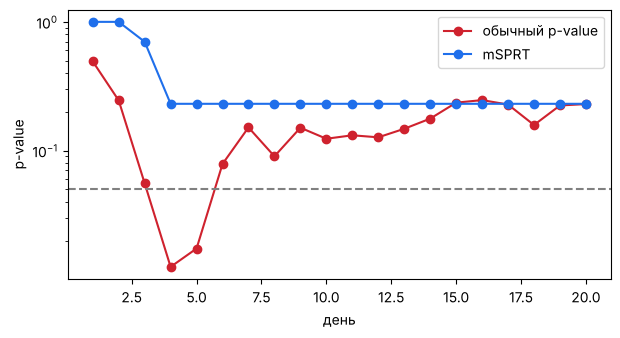

In [6]:
rng = np.random.default_rng(3)
aa = make_experiment(40_000, seed=11).sample(frac=1, random_state=3)   # A/A, порядок прихода
c = aa[aa.group == "A"].revenue.to_numpy()
t = aa[aa.group == "B"].revenue.to_numpy()
n = min(len(c), len(t))
looks = [round(n * (k + 1) / 20) for k in range(20)]
naive_p = [hb.welch(c[:m], t[:m]).p_value for m in looks]
seq = hb.msprt(c[:n], t[:n], looks=looks)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 21), naive_p, "o-", color="#cf222e", label="обычный p-value")
ax.plot(range(1, 21), [lk.p_value for lk in seq.looks], "o-", color="#1f6feb", label="mSPRT")
ax.axhline(0.05, ls="--", color="gray")
ax.set_xlabel("день"); ax.set_ylabel("p-value"); ax.set_yscale("log"); ax.legend()
plt.show()

Насколько это опасно в среднем, показывает `validation/VALIDATION.md`: при 20 проверках
обычный t-тест находит «эффект» примерно в четверти A/A-тестов.

## 6. Байесовский взгляд на конверсию

Для общения с бизнесом удобна формулировка «вероятность, что B лучше». Это не заменяет
заранее зафиксированный тест и не делает подглядывание безопасным.

In [7]:
a, b = df[df.group == "A"], df[df.group == "B"]
r = hb.bayes.beta_binomial(a.converted.sum(), len(a), b.converted.sum(), len(b))
print(f"P(B лучше A) = {r.prob_treatment_better:.1%}; "
      f"95% интервал относительного эффекта: {r.rel_effect_ci[0]:+.1%} … {r.rel_effect_ci[1]:+.1%}")

P(B лучше A) = 78.7%; 95% интервал относительного эффекта: -2.7% … +6.7%


## Итог

- **Выручка:** истинный эффект +8%; отчёт показал +11.7% с 95% ДИ от +5.3% до +18.6% —
  интервал накрывает правду, а точечная оценка из-за шума выше. Поэтому в решении важен
  интервал, а не одно число.
- **CTR:** истинный эффект +4%; найден +3.2% (ДИ +0.7% … +5.7%), значим и после поправки Holm.
- **Конверсия** не менялась — и отчёт не нашёл в ней эффекта.
- **Guardrail** (сессии) не ухудшился, SRM в порядке → решение «катить» обосновано.
- По просмотрам CTR «находит эффект» вдвое чаще положенного; дельта-метод держит около 5%.